# News Sentiment for Stocks and Credit: FinBERT vs an Open LLM vs a Finance Word List, and What Headlines Say About Next-Day Returns and Spreads

Every trading desk now has some kind of news-sentiment score. The useful question is not whether headlines sound positive or negative, but whether that tone tells you anything you did not already see in the price. This notebook measures sentiment three ways on almost nine years of headlines and checks what each version is actually worth.

**What it does.** It collects the news headlines on ten large U.S. companies since 2018 from four sources: the **FNSPID** financial-news dataset, the companies' own **SEC 8-K** press releases, the complete **New York Times** archive and **The Guardian**. Their sentiment is measured three ways:

1. a **finance word list** in the spirit of Loughran and McDonald;
2. **FinBERT**, a BERT model fine-tuned on financial text;
3. an open instruction-tuned **LLM** (Qwen2.5-1.5B-Instruct), asked zero-shot whether each headline is good or bad news for the company's stock.

It then asks how closely sentiment tracks same-day returns, whether it predicts next-day abnormal returns, and whether aggregate corporate news sentiment leads high-yield credit.

**Data.** FNSPID (Hugging Face), SEC EDGAR 8-K filings, the New York Times Archive API, The Guardian Open Platform API (headlines with timestamps), Yahoo Finance (stock, SPY and HYG/IEF prices) and FRED (ICE BofA US High Yield OAS).

**Methods.** Hugging Face `transformers` pipelines (ProsusAI/finbert), zero-shot LLM scoring from next-token probabilities, and agreement statistics (Cohen's κ, correlations).

The return tests are daily panel regressions with date-clustered errors and quintile event studies of abnormal returns; the credit test is a set of lead–lag regressions on spreads.

**Key output.** How often the three measures agree, how they relate to same-day and next-day returns, and the credit signal.

## 1. Three ways to read a headline

| method | how it works | cost |
|---|---|---|
| **word list** | counts positive and negative finance words in each headline (in the spirit of Loughran and McDonald, 2011) | free, instant |
| **FinBERT** | BERT fine-tuned on financial news with positive / negative / neutral labels (Araci, 2019) | 110 million parameters, fast on a CPU |
| **open LLM** | Qwen2.5-1.5B-Instruct asked "is this good, bad or neutral news for the stock of X?"; the probabilities of the three answer words give the score | 1.5 billion parameters, about one second per headline on a CPU; no API cost |

The LLM is the only one that knows *which company* the question is about. "Boeing shares fall as rival Airbus wins order" is bad news for Boeing and good news for Airbus, but FinBERT and word lists see a single sentiment.

**The key distinction is timing.** Headlines about stock moves are written after the move ("Tesla shares jump after earnings"), so same-day correlations with returns are high by construction.

A sentiment measure is useful for **trading or risk** only if it helps predict the next day. The tests below keep the two apart.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import torch
import transformers
import yfinance as yf
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score
from transformers import (
    AutoModelForCausalLM,
    AutoModelForSequenceClassification,
    AutoTokenizer,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 79
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
COMPANIES = {
    "AAPL": "Apple",
    "MSFT": "Microsoft",
    "AMZN": "Amazon",
    "TSLA": "Tesla",
    "NVDA": "Nvidia",
    "JPM": "JPMorgan",
    "BA": "Boeing",
    "XOM": "Exxon",
    "PFE": "Pfizer",
    "INTC": "Intel",
}
START, LLM_SAMPLE = "2018-01-01", 4000
NYT_NAMES = {
    "AAPL": r"\bApple\b",
    "MSFT": r"\bMicrosoft\b",
    "AMZN": r"\bAmazon\b",
    "TSLA": r"\bTesla\b",
    "NVDA": r"\bNvidia\b",
    "JPM": r"\bJPMorgan\b|\bJ\.P\. Morgan\b",
    "BA": r"\bBoeing\b",
    "XOM": r"\bExxon",
    "PFE": r"\bPfizer\b",
    "INTC": r"\bIntel\b",
}
# headlines collected up to this date (fixed, so the cached downloads stay
# valid)
NEWS_AS_OF = pd.Timestamp("2026-10-20")
FINBERT, LLM = "ProsusAI/finbert", "Qwen/Qwen2.5-1.5B-Instruct"

print(
    f"transformers {transformers.__version__} · torch {torch.__version__} ·"
    f" yfinance {yf.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

…/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


transformers 5.20.1 · torch 2.14.1+cu130 · yfinance 1.7.0 · run on 2026-10-22


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- News sources: NYT Archive API, The Guardian Open Platform, FNSPID
# (Hugging Face), SEC 8-K filings
# Free keys go in .env:  NYT_API_KEY (developer.nytimes.com, Archive API)  ·
# GUARDIAN_API_KEY (open-platform.theguardian.com)
import csv
import gzip
import json
import sys

NYT_KEY, GUARDIAN_KEY = (
    os.getenv("NYT_API_KEY", "").strip(),
    os.getenv("GUARDIAN_API_KEY", "").strip(),
)
NYT_DIR = DATA_DIR / "nyt_archive"
NYT_DIR.mkdir(exist_ok=True)
_NYT_KEEP = [
    "pub_date",
    "section_name",
    "news_desk",
    "type_of_material",
    "document_type",
    "word_count",
    "web_url",
]


def nyt_month(m):
    """
    Every article the New York Times published in month m (metadata only),
    cached as gzip JSON in data/nyt_archive/.
    """
    path = NYT_DIR / f"{m}.json.gz"
    if path.exists():
        return pd.DataFrame(json.load(gzip.open(path, "rt")))
    if not NYT_KEY:
        raise RuntimeError(
            "NYT_API_KEY not found in .env (free key at developer.nytimes.com,"
            " Archive API)."
        )
    for k in range(6):
        r = requests.get(
            f"https://api.nytimes.com/svc/archive/v1/{m.year}/{m.month}.json",
            params={"api-key": NYT_KEY},
            timeout=180,
        )
        if r.status_code == 200:
            rows = [
                {
                    **{c: d.get(c) for c in _NYT_KEEP},
                    "headline": (d.get("headline") or {}).get("main"),
                    "abstract": d.get("abstract"),
                    "lead": d.get("lead_paragraph"),
                    "keywords": "; ".join(
                        f"{x.get('name')}:{x.get('value')}"
                        for x in (d.get("keywords") or [])
                    ),
                }
                for d in r.json()["response"]["docs"]
            ]
            with gzip.open(path, "wt") as fh:
                json.dump(rows, fh)
            # the Archive API allows about five requests a minute
            time.sleep(13)
            return pd.DataFrame(rows)
        time.sleep(60 * (k + 1))
    raise RuntimeError(f"NYT Archive API not answering for {m}")


def nyt_archive(start, end):
    months = pd.period_range(start, end, freq="M")
    A = pd.concat(
        [nyt_month(m).assign(month=str(m)) for m in months], ignore_index=True
    )
    A["date"] = pd.to_datetime(A["pub_date"], utc=True, errors="coerce")
    return A


def guardian_search(params):
    """
    One Guardian Content API request (12 per second and 5,000 a day are allowed
    on the free tier; this client is slower).
    """
    if not GUARDIAN_KEY:
        raise RuntimeError(
            "GUARDIAN_API_KEY not found in .env (free key at"
            " open-platform.theguardian.com)."
        )
    for k in range(6):
        try:
            r = requests.get(
                "https://content.guardianapis.com/search",
                params={**params, "api-key": GUARDIAN_KEY},
                timeout=60,
            )
            if r.status_code == 200:
                time.sleep(1.1)
                return r.json()["response"]
            time.sleep(30 * (k + 1))
        except requests.RequestException:
            time.sleep(30)
    return {"results": [], "pages": 0}


def guardian_rows(resp, **extra):
    return [
        {
            "date": x.get("webPublicationDate"),
            "title": x.get("webTitle"),
            "section": x.get("sectionName"),
            "trail": (x.get("fields") or {}).get("trailText"),
            **extra,
        }
        for x in resp.get("results", [])
    ]


def guardian_companies(queries, start, end):
    """
    Every Guardian business, technology or money article that names the company
    together with a markets word.
    """
    out = []
    for tk, q in queries.items():
        base = {
            "q": (
                f"{q} AND (shares OR stock OR earnings OR investors OR profit"
                " OR revenue)"
            ),
            "section": "business|technology|money",
            "from-date": start,
            "to-date": end,
            "page-size": 200,
            "show-fields": "trailText",
            "order-by": "oldest",
        }
        first = guardian_search({**base, "page": 1})
        out += guardian_rows(first, ticker=tk)
        for pg in range(2, int(first.get("pages", 0)) + 1):
            out += guardian_rows(
                guardian_search({**base, "page": pg}), ticker=tk
            )
    return pd.DataFrame(out)


FNSPID_URL = "https://huggingface.co/datasets/sabareesh88/FNSPID_nasdaq/resolve/main/data/train-{:05d}-of-00048.parquet"


def fnspid_headlines(tickers):
    """
    FNSPID (Dong, Fan and Peng, 2024), Nasdaq.com news file on Hugging Face (48
    Parquet shards, 10.6 GB): reads over HTTP only the
    row groups whose symbol range contains one of the tickers, and only four
    columns, so a few hundred MB are transferred.
    """
    import fsspec
    import pyarrow.parquet as pq

    T, fs, keep = (
        set(tickers),
        fsspec.filesystem("https", client_kwargs={"trust_env": True}),
        [],
    )
    for i in range(48):
        f = pq.ParquetFile(fs.open(FNSPID_URL.format(i), block_size=2**22))
        j = f.schema_arrow.names.index("Stock_symbol")
        for g in range(f.metadata.num_row_groups):
            st = f.metadata.row_group(g).column(j).statistics
            if (
                st is None
                or not st.has_min_max
                or any(st.min <= t <= st.max for t in T)
            ):
                d = f.read_row_group(
                    g,
                    columns=[
                        "Date",
                        "Article_title",
                        "Stock_symbol",
                        "Publisher",
                    ],
                ).to_pandas()
                keep.append(
                    d[d["Stock_symbol"].astype(str).str.upper().isin(T)]
                )
    return pd.concat(keep, ignore_index=True).drop_duplicates(
        ["Date", "Article_title", "Stock_symbol"]
    )


ITEMS_8K = {
    "1.01": "entry into a material agreement",
    "1.02": "termination of a material agreement",
    "1.03": "bankruptcy or receivership",
    "2.01": "completion of an acquisition or disposition",
    "2.02": "results of operations and financial condition",
    "2.03": "new direct financial obligation",
    "2.05": "exit or restructuring costs",
    "2.06": "material impairment",
    "3.01": "delisting notice",
    "3.03": "change to the rights of security holders",
    "4.01": "change of auditor",
    "4.02": "non-reliance on previous financial statements",
    "5.02": "departure or appointment of directors or officers",
    "5.03": "amendment to articles or bylaws",
    "5.07": "shareholder vote results",
    "7.01": "Regulation FD disclosure",
    "8.01": "other material events",
    "9.01": "financial statements and exhibits",
}
# Exxon Mobil Corp filed under this CIK until its 2026 holding-company
# reorganisation
SEC_EXTRA_CIK = {"XOM": ["0000034088"]}


def sec_8k(tickers, start):
    """
    Every 8-K a company filed since `start`: acceptance time, item codes, and
    the headline and opening text of its press release (EX-99).
    """
    import html as _html

    H = {
        "User-Agent": os.getenv(
            "SEC_USER_AGENT", "research contact@example.com"
        )
    }

    def get(url, js=True):
        for k in range(6):
            time.sleep(0.13)
            try:
                r = requests.get(url, headers=H, timeout=60)
                if r.status_code == 200:
                    return r.json() if js else r.text
                if r.status_code == 404:
                    return None
            except requests.RequestException:
                pass
            time.sleep(5 * (k + 1))
        return None

    skip = re.compile(
        r"exhibit|press release|for immediate release|news"
        r" release|contact|investor relations|media relations|^page"
        r" \d|^\(?\d|^[\W_]*$|^[A-Z][a-z]+ \d{1,2}, \d{4}$|^\w+, \w+ \d",
        re.I,
    )

    def head_text(raw):
        raw = re.sub(r"(?is)<(script|style).*?</\1>", " ", raw)
        raw = re.sub(r"(?i)<br\s*/?>|</(p|div|tr|h\d|li)>", "\n", raw)
        lines = [
            re.sub(r"\s+", " ", x).strip()
            for x in _html.unescape(re.sub(r"<[^>]+>", " ", raw))
            .replace("\xa0", " ")
            .split("\n")
        ]
        lines = [x for x in lines if x]
        return (
            next(
                (
                    x
                    for x in lines[:40]
                    if not skip.search(x) and 4 <= len(x.split()) <= 30
                ),
                None,
            ),
            " ".join(lines)[:3000],
        )

    cik = {
        v["ticker"]: str(v["cik_str"]).zfill(10)
        for v in get("https://www.sec.gov/files/company_tickers.json").values()
    }
    out = []
    for tk, c in [(t, cik[t]) for t in tickers] + [
        (t, x) for t, xs in SEC_EXTRA_CIK.items() if t in tickers for x in xs
    ]:
        sub = get(f"https://data.sec.gov/submissions/CIK{c}.json")
        F = pd.concat(
            [pd.DataFrame(sub["filings"]["recent"])]
            + [
                pd.DataFrame(
                    get(f"https://data.sec.gov/submissions/{f['name']}")
                )
                for f in sub["filings"].get("files", [])
            ]
        )
        for _, r in F[
            F["form"].isin(["8-K", "8-K/A"]) & (F["filingDate"] >= start)
        ].iterrows():
            base = (
                f"https://www.sec.gov/Archives/edgar/data/{int(c)}/{r['accessionNumber'].replace('-', '')}"
            )
            names = [
                x["name"]
                for x in (
                    (get(f"{base}/index.json") or {})
                    .get("directory", {})
                    .get("item", [])
                )
            ]
            ex = sorted(
                [
                    x
                    for x in names
                    if re.search(r"ex-?99|dex99", x, re.I)
                    and x.lower().endswith((".htm", ".html", ".txt"))
                ],
                key=lambda x: (
                    0 if re.search(r"99[-_.]?0?1|991", x) else 1,
                    x,
                ),
            )
            raw = get(f"{base}/{ex[0]}", js=False) if ex else None
            h, t = head_text(raw) if raw else (None, None)
            out.append({
                "acc": r["accessionNumber"],
                "ticker": tk,
                "form": r["form"],
                "filed": r["filingDate"],
                "accepted": r["acceptanceDateTime"],
                "items": r.get("items", ""),
                "exhibit": ex[0] if ex else None,
                "headline": h,
                "text": t,
            })
    return pd.DataFrame(out)


def sec_8k_titles(K, names):
    """
    One headline per 8-K: the press-release headline when it reads like one,
    otherwise '<Company> 8-K: <item descriptions>'.
    """
    good = K["headline"].fillna("").str.len().between(25, 250) & ~K[
        "headline"
    ].fillna("").str.contains(
        r"\d{5}|financial supplement|for release|^(?:the )?[\w.&,\- ]+"
        r" (?:inc|corp|corporation|company|co)\.?$",
        regex=True,
        case=False,
    )
    desc = (
        K["items"]
        .fillna("")
        .map(
            lambda s: "; ".join(
                ITEMS_8K[x]
                for x in s.split(",")
                if x in ITEMS_8K and x != "9.01"
            )
        )
    )
    title = np.where(
        good, K["headline"], K["ticker"].map(names) + " 8-K: " + desc
    )
    # The submissions API labels acceptance times "Z" but they run ahead of
    # true UTC by the New York UTC offset (checked against the filing
    # index pages: 16:30 New York time appears as 00:30Z in summer and 02:30Z
    # in winter). Two conversions recover the New York time.
    t = (
        pd.to_datetime(K["accepted"], utc=True, errors="coerce")
        .dt.tz_convert("America/New_York")
        .dt.tz_localize(None)
    )
    t = t.dt.tz_localize("UTC").dt.tz_convert("America/New_York")
    return K.assign(title=title, date=t.astype(str))[
        ["ticker", "date", "title", "items"]
    ]


# Compact finance word lists in the spirit of Loughran and McDonald (2011): a
# dictionary benchmark for the language models
POS_WORDS = r"\b(beat|beats|gain|gains|gained|surge|surges|surged|soar|soared|record|strong|stronger|growth|grow|grows|profit|profits|upgrade|upgraded|rally|rallies|rallied|rise|rises|rose|boost|boosted|outperform\w*|exceed\w*|improv\w*|win|wins|approval|approved)\b"
NEG_WORDS = r"\b(miss|misses|missed|loss|losses|lose|loses|lost|fall|falls|fell|drop|drops|dropped|plunge\w*|slump\w*|weak|weaker|cut|cuts|downgrade\w*|lawsuit\w*|probe|fine|fined|recall\w*|decline\w*|warn\w*|layoff\w*|risk|risks|crash\w*|fraud|default\w*|bankrupt\w*)\b"


def wordlist_tone(texts):
    t = pd.Series(texts).fillna("")
    pos, neg = t.str.count(POS_WORDS, flags=re.I), t.str.count(
        NEG_WORDS, flags=re.I
    )
    return ((pos - neg) / (pos + neg).replace(0, np.nan)).fillna(0).values

## 3. Collecting headlines from four sources

- **FNSPID** (Dong, Fan and Peng, 2024): time-stamped financial news on S&P 500 companies from Nasdaq.com, Benzinga, Reuters and others, published on Hugging Face up to the end of 2023 (10.6 GB in 48 Parquet files). The file is sorted by ticker, so only the blocks that contain these ten companies are read over the internet, and only four columns.
- **SEC 8-K filings**: every current report the companies filed since 2018 (results, acquisitions, executive changes and other material events), with the exact acceptance time. When a filing carries a press release (exhibit 99), its headline is used, for example "Microsoft Cloud Strength Fuels Third Quarter Results". Filings without a usable headline are left out of the sentiment, because a list of item codes carries no tone.
- **The New York Times archive**: every article of every month (via the Archive API), kept when the headline or abstract names the company and the article ran in the business or technology pages.
- **The Guardian** (Open Platform API): every business, technology or money article that names the company together with a markets word (shares, stock, earnings, investors, profit, revenue).

Together they give continuous coverage from 2018 to October 2026: FNSPID is dense to 2023 for most of the companies (to mid-2020 for JPMorgan and Pfizer), and the 8-Ks and the two newspapers cover the whole period. Duplicated titles are dropped. The source of each headline is kept, because wire-style FNSPID headlines, company press releases and newspaper headlines are written differently.

**Timing rule:** a headline is assigned to trading day d if it was published before 16:00 New York time on d. Later headlines, and weekend ones, go to the next trading day. "Next-day" returns are then the close-to-close return of the following trading day, after every headline counted for day d was public.

**Word-list tone**: a dictionary benchmark in the spirit of Loughran and McDonald (2011), the share of positive minus negative finance words in each headline.

In [3]:
def fetch_fnspid():
    f = fnspid_headlines(list(COMPANIES))
    return f.rename(
        columns={
            "Date": "date",
            "Article_title": "title",
            "Stock_symbol": "ticker",
            "Publisher": "publisher",
        }
    )


def fetch_nyt_company():
    A = nyt_archive(pd.Period(START, "M"), NEWS_AS_OF.to_period("M"))
    biz = A["section_name"].isin(
        ["Business Day", "Technology", "Your Money"]
    ) | A["news_desk"].fillna("").str.contains(
        "Business|Technology|DealBook|Money"
    )
    A = A[biz].copy()
    A["text"] = A["headline"].fillna("") + " " + A["abstract"].fillna("")
    out = [
        A[A["text"].str.contains(rx, regex=True)].assign(ticker=tk)
        for tk, rx in NYT_NAMES.items()
    ]
    return (
        pd.concat(out)[["ticker", "date", "headline"]]
        .rename(columns={"headline": "title"})
        .assign(date=lambda d: d["date"].astype(str))
    )


F_ = cached("fnspid_selected", fetch_fnspid, max_age_hours=24 * 365)
N_ = cached("nyt_company_headlines", fetch_nyt_company, max_age_hours=24 * 30)
K_ = cached(
    "sec_8k_filings",
    lambda: sec_8k(list(COMPANIES), START),
    max_age_hours=24 * 30,
)
E_ = sec_8k_titles(K_[K_["ticker"].isin(COMPANIES)], COMPANIES)
E_ = E_[~E_["title"].str.contains(" 8-K: ", regex=False)]
G_ = cached(
    "guardian_companies",
    lambda: guardian_companies(
        {k: f'"{v}"' for k, v in COMPANIES.items()},
        START,
        f"{NEWS_AS_OF:%Y-%m-%d}",
    ),
    max_age_hours=24 * 30,
)
F_ = F_[F_["ticker"].isin(COMPANIES)]
G_ = G_[G_["ticker"].isin(COMPANIES)]
NEWS = pd.concat(
    [
        F_[["ticker", "date", "title"]].assign(source="FNSPID"),
        E_[["ticker", "date", "title"]].assign(source="SEC 8-K"),
        N_.assign(source="New York Times"),
        G_[["ticker", "date", "title"]].assign(source="The Guardian"),
    ],
    ignore_index=True,
)
NEWS["seen_ny"] = (
    pd.to_datetime(
        NEWS["date"].astype(str).str.replace(" UTC", "", regex=False),
        utc=True,
        errors="coerce",
        format="mixed",
    )
    .dt.tz_convert("America/New_York")
    .dt.tz_localize(None)
)
NEWS = NEWS[(NEWS["seen_ny"] >= START) & (NEWS["seen_ny"] <= NEWS_AS_OF)]
NEWS["title"] = (
    NEWS["title"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
)
NEWS = (
    NEWS[NEWS["title"].str.len() > 25]
    .drop_duplicates(["ticker", "title"])
    .sort_values(["ticker", "seen_ny"])
    .reset_index(drop=True)
)
NEWS["wordlist"] = wordlist_tone(NEWS["title"])
print(
    f"{len(NEWS):,} unique headlines {NEWS['seen_ny'].min():%Y-%m} →"
    f" {NEWS['seen_ny'].max():%Y-%m}"
)
pd.crosstab(NEWS["ticker"], NEWS["source"]).assign(total=lambda d: d.sum(1))

75,342 unique headlines 2018-01 → 2026-10


/tmp/ipykernel_5069/115410078.py:30: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pd.crosstab(NEWS["ticker"], NEWS["source"]).assign(total=lambda d: d.sum(1))


source,FNSPID,New York Times,SEC 8-K,The Guardian,total
ticker,,,,,
AAPL,8098,766,12,1472,10348
AMZN,4495,836,19,1804,7154
BA,5420,343,32,536,6331
INTC,9902,69,9,190,10170
JPM,2730,155,6,234,3125
MSFT,7508,353,42,1014,8917
NVDA,9188,125,2,522,9837
PFE,923,32,52,302,1309
TSLA,9692,575,70,1103,11440


In [4]:
def fetch_px():
    px = yf.download(
        list(COMPANIES) + ["SPY", "HYG", "IEF"],
        start="2017-12-01",
        auto_adjust=True,
        progress=False,
    )["Close"]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name = "date"
    return px.reset_index()


PX = (
    cached("prices", fetch_px, max_age_hours=24).set_index("date").sort_index()
)
PX = PX[PX.index < pd.Timestamp.today().normalize()]
RET = np.log(PX).diff()
days = PX.index
cut = NEWS["seen_ny"].dt.normalize() + pd.Timedelta(hours=16)
eff = np.where(
    NEWS["seen_ny"] < cut,
    NEWS["seen_ny"].dt.normalize(),
    NEWS["seen_ny"].dt.normalize() + pd.Timedelta(days=1),
)
pos = np.searchsorted(days.values, eff.astype("datetime64[ns]"))
NEWS["day"] = [days[p] if p < len(days) else pd.NaT for p in pos]
NEWS = NEWS.dropna(subset=["day"])
print(
    f"Headlines mapped to {NEWS['day'].nunique():,} trading days ·"
    f" {days[0]:%Y-%m-%d} → {days[-1]:%Y-%m-%d}"
)

Headlines mapped to 2,174 trading days · 2017-12-01 → 2026-10-21


## 4. Scoring: FinBERT on every headline, the LLM on a sample

**FinBERT** (`ProsusAI/finbert`) scores all headlines, giving positive, negative and neutral probabilities. The sentiment is P(positive) − P(negative).

**The LLM** scores a stratified random sample of 4,000 headlines (400 per company); a full pass over every headline would take days on a CPU. The prompt names the company: *"Headline: … Is this headline good news, bad news or neutral for the stock of {company}?

Answer with one word: positive, negative or neutral."* The probabilities of the three answer tokens are renormalised, and the sentiment is again P(positive) − P(negative).

In [5]:
fb_tok = AutoTokenizer.from_pretrained(FINBERT)
fb = AutoModelForSequenceClassification.from_pretrained(FINBERT).eval()
FB_LABELS = [fb.config.id2label[i].lower() for i in range(3)]


def finbert_scores(titles, batch=64):
    out = []
    for i in range(0, len(titles), batch):
        enc = fb_tok(
            titles[i : i + batch],
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=64,
        )
        with torch.no_grad():
            out.append(torch.softmax(fb(**enc).logits, -1).numpy())
    p = np.vstack(out)
    return pd.DataFrame(p, columns=[f"fb_{l}" for l in FB_LABELS])


t0 = time.time()
FB = pd.concat(
    [
        cached(
            f"finbert_scores_{tk}",
            lambda tk=tk: finbert_scores(
                NEWS.loc[NEWS["ticker"] == tk, "title"].tolist()
            ),
            max_age_hours=24 * 30,
        )
        # one cache per company: resumable
        for tk in NEWS["ticker"].unique()
    ],
    ignore_index=True,
)
NEWS = pd.concat(
    [NEWS.reset_index(drop=True), FB.reset_index(drop=True)], axis=1
)
NEWS["finbert"] = NEWS["fb_positive"] - NEWS["fb_negative"]
print(
    f"FinBERT: {len(NEWS):,} headlines in {time.time() - t0:.0f}s (cached"
    " after the first run)"
)

tok = AutoTokenizer.from_pretrained(LLM)
tok.padding_side = "left"
# bfloat16 weights: about 3 GB
llm = AutoModelForCausalLM.from_pretrained(LLM, dtype=torch.bfloat16).eval()
IDS = [
    tok.encode(w, add_special_tokens=False)
    for w in ["positive", "negative", "neutral"]
]
assert all(len(i) == 1 for i in IDS), "each answer word must be a single token"
IDS = [i[0] for i in IDS]


def llm_scores(df, batch=16):
    out = []
    for i in range(0, len(df), batch):
        part = df.iloc[i : i + batch]
        texts = [
            tok.apply_chat_template(
                [{
                    "role": "user",
                    "content": (
                        f"Headline: {t}\nIs this headline good news, bad news"
                        f" or neutral for the stock of {COMPANIES[k]}? Answer"
                        " with one word: positive, negative or neutral."
                    ),
                }],
                tokenize=False,
                add_generation_prompt=True,
            )
            for t, k in zip(part["title"], part["ticker"])
        ]
        enc = tok(texts, return_tensors="pt", padding=True)
        with torch.no_grad():
            out.append(
                torch.softmax(
                    llm(**enc).logits[:, -1, IDS].float(), -1
                ).numpy()
            )
    p = np.vstack(out)
    return pd.DataFrame(
        {
            "llm_positive": p[:, 0],
            "llm_negative": p[:, 1],
            "llm_neutral": p[:, 2],
        },
        index=df.index,
    )


# equal random sample per company
samp_idx = (
    NEWS.sample(frac=1, random_state=SEED)
    .groupby("ticker")
    .head(LLM_SAMPLE // len(COMPANIES))
    .index
)
t0 = time.time()
LL = pd.concat([
    cached(
        f"llm_scores_{tk}",
        lambda tk=tk: llm_scores(
            NEWS.loc[samp_idx][NEWS.loc[samp_idx, "ticker"] == tk]
        ).reset_index(names="row"),
        max_age_hours=24 * 30,
    )
    # cached company by company, so an interrupted run resumes
    for tk in COMPANIES
]).set_index("row")
NEWS = NEWS.join(LL)
NEWS["llm"] = NEWS["llm_positive"] - NEWS["llm_negative"]
print(
    f"LLM: {LL.shape[0]:,} headlines in {time.time() - t0:.0f}s (cached after"
    " the first run)"
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT: 75,342 headlines in 0s (cached after the first run)


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

LLM: 4,000 headlines in 0s (cached after the first run)


## 5. Do the three measures agree?

On the LLM sample, each headline gets a label from each model (the highest probability). Agreement is measured with Cohen's κ (0 = chance, 1 = perfect), plus the rank correlation of the continuous scores. The table of disagreements shows where reading the company name matters.

In [6]:
S = NEWS.dropna(subset=["llm"]).copy()
lab = lambda p, n, u: np.select(
    [(p > n) & (p > u), (n > p) & (n > u)], ["positive", "negative"], "neutral"
)
S["fb_label"] = lab(S["fb_positive"], S["fb_negative"], S["fb_neutral"])
S["llm_label"] = lab(S["llm_positive"], S["llm_negative"], S["llm_neutral"])
AGREE = pd.Series({
    "headlines": len(S),
    "same label (%)": 100 * (S["fb_label"] == S["llm_label"]).mean(),
    "Cohen's kappa": cohen_kappa_score(S["fb_label"], S["llm_label"]),
    "rank corr of scores": spearmanr(S["finbert"], S["llm"])[0],
    "opposite sign (%)": (
        100
        * (
            (S["fb_label"] == "positive") & (S["llm_label"] == "negative")
            | (S["fb_label"] == "negative") & (S["llm_label"] == "positive")
        ).mean()
    ),
})
CROSS = pd.crosstab(
    S["fb_label"], S["llm_label"], rownames=["FinBERT"], colnames=["LLM"]
)
DIS = S[
    (S["fb_label"] != S["llm_label"])
    & (S["fb_label"] != "neutral")
    & (S["llm_label"] != "neutral")
][["ticker", "title", "finbert", "llm"]].head(10)
display(AGREE.round(3).to_frame("value"))
display(CROSS)
DIS.round(2)

,value
headlines,"4,000.00"
same label (%),59.73
Cohen's kappa,0.21
rank corr of scores,0.63
opposite sign (%),0.82


LLM,negative,neutral,positive
FinBERT,,,
negative,127,783,27
neutral,28,1949,211
positive,6,556,313


,ticker,title,finbert,llm
12191,AMZN,Stocks climb as investors weigh a surprising j...,-0.76,0.89
12795,AMZN,Oppenheimer Maintains Amazon.com (AMZN) Outper...,-0.59,0.89
18865,BA,"Wall St inches higher on Facebook, Boeing boun...",-0.07,0.92
19329,BA,7 Dow Titans Breaking Higher,-0.22,0.84
19342,BA,Southwest Airlines' Unit Costs Will Plummet in...,-0.94,0.53
19936,BA,Stock Alert: Boeing Surges On Consecutive Day,-0.48,1.00
20164,BA,U.S. stocks rally on coronavirus drug hopes,-0.88,0.85
21529,BA,Families of crash victims want U.S. to rescind...,0.40,-0.53
25078,INTC,Nvidia Stock Is Bound to Be the AI Superstar W...,-0.47,0.62
28671,INTC,5 Semiconductor Stocks Set for Rebound Post Co...,-0.56,0.59


## 6. Sentiment and returns: same day vs next day

Daily company sentiment is the average score of the headlines assigned to each trading day, for FinBERT and the word list (all headlines) and the LLM (sampled headlines only). The abnormal return is the stock's log return minus SPY's.

Two panel regressions per measure, with standardised sentiment, firm fixed effects and errors clustered by date:
- **same day:** AR_{i,d} on sentiment_{i,d}, the "news describes the move" relation;
- **next day:** AR_{i,d+1} on sentiment_{i,d}, the predictive relation.

Quintile sorts show the average next-day abnormal return by sentiment bucket.

In [7]:
AR = RET[list(COMPANIES)].sub(RET["SPY"], axis=0)
P_ = (
    NEWS.groupby(["ticker", "day"])
    .agg(
        finbert=("finbert", "mean"),
        llm=("llm", "mean"),
        wordlist=("wordlist", "mean"),
        n=("title", "size"),
    )
    .reset_index()
)
ar_l = (
    AR.stack()
    .rename("ar")
    .reset_index()
    .rename(columns={"level_1": "ticker", "date": "day"})
)
ar_l.columns = ["day", "ticker", "ar"]
ar_next = ar_l.copy()
ar_next["day"] = ar_next.groupby("ticker")["day"].shift(1)
ar_next = ar_next.rename(columns={"ar": "ar_next"}).dropna()
P_ = P_.merge(ar_l, on=["ticker", "day"], how="left").merge(
    ar_next, on=["ticker", "day"], how="left"
)
# company-day sentiment, used for the index and the exported scores
daily = P_[["ticker", "day", "finbert", "llm", "wordlist", "n"]].copy()


def clustered_ols(df, y, x):
    d = df.dropna(subset=[y, x]).copy()
    d[x] = (d[x] - d[x].mean()) / d[x].std()
    d[y + "_dm"] = d[y] - d.groupby("ticker")[y].transform("mean")
    d[x + "_dm"] = d[x] - d.groupby("ticker")[x].transform("mean")
    b = (d[x + "_dm"] * d[y + "_dm"]).sum() / (d[x + "_dm"] ** 2).sum()
    e = d[y + "_dm"] - b * d[x + "_dm"]
    g = (d[x + "_dm"] * e).groupby(d["day"]).sum()
    se = np.sqrt((g**2).sum()) / (d[x + "_dm"] ** 2).sum()
    return b * 1e4, b / se, len(d)


rows = []
for m in ["wordlist", "finbert", "llm"]:
    for y, lab_ in [("ar", "same day"), ("ar_next", "next day")]:
        b, t, n = clustered_ols(P_, y, m)
        rows.append({
            "measure": m,
            "horizon": lab_,
            "bp per 1 s.d. of sentiment": b,
            "t-stat (clustered by date)": t,
            "firm-days": n,
        })
REG = pd.DataFrame(rows).pivot(index="measure", columns="horizon")
# same comparison restricted to days where all three measures exist
common = P_.dropna(subset=["finbert", "llm", "wordlist", "ar_next"])
rows_c = []
for m in ["wordlist", "finbert", "llm"]:
    b, t, n = clustered_ols(common, "ar_next", m)
    b0, t0_, _ = clustered_ols(common, "ar", m)
    rows_c.append({
        "measure": m,
        "same-day bp": b0,
        "same-day t": t0_,
        "next-day bp": b,
        "next-day t": t,
        "firm-days": n,
    })
REG_C = pd.DataFrame(rows_c).set_index("measure")
Q = P_.dropna(subset=["finbert", "ar_next"]).copy()
Q["q"] = Q.groupby("ticker")["finbert"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1
)
QT = (
    Q.groupby("q")[["ar", "ar_next"]]
    .mean()
    .mul(1e4)
    .rename(columns={"ar": "same-day AR (bp)", "ar_next": "next-day AR (bp)"})
)
display(REG.round(2))
display(REG_C.round(2))
QT.round(1)

bp per 1 s.d. of sentiment          t-stat (clustered by date)  \
horizon                    next day same day                   next day   
measure                                                                   
finbert                        3.23    26.82                       1.57   
llm                            0.53    34.93                       0.10   
wordlist                      -1.29    15.81                      -0.66   

                  firm-days           
horizon  same day  next day same day  
measure                               
finbert     11.78     12256    12256  
llm          6.28      2960     2960  
wordlist     7.17     12256    12256

,same-day bp,same-day t,next-day bp,next-day t,firm-days
measure,,,,,
wordlist,31.22,6.17,1.28,0.31,2960
finbert,45.68,8.70,5.44,1.27,2960
llm,34.93,6.28,0.53,0.10,2960


,same-day AR (bp),next-day AR (bp)
q,,
1,-41.20,-4.70
2,-32.70,-2.60
3,8.00,-3.80
4,34.80,9.60
5,36.40,6.30


## 7. Does corporate news lead credit?

The ten companies' daily FinBERT sentiment is averaged into one index (its 5-day mean). Two lead–lag regressions follow:
- **ETF test:** the next 5-day excess return of HYG over IEF (high yield minus duration-matched Treasuries, which removes rates) on the index, 2020 to today;
- **spread test:** the next 5-day change in the ICE BofA US High Yield OAS on the index. FRED keeps only about three years of this series.

Errors are Newey–West with 5 lags, because the 5-day windows overlap.

In [8]:
idx_s = (
    daily.pivot(index="day", columns="ticker", values="finbert")
    .reindex(days)
    .mean(axis=1)
    .rolling(5, min_periods=3)
    .mean()
)
hy_ex = (RET["HYG"] - RET["IEF"]).rolling(5).sum().shift(-5)
oas = fred.get_series("BAMLH0A0HYM2").dropna()
oas.index = pd.to_datetime(oas.index)
d_oas = (oas.reindex(days).ffill().shift(-5) - oas.reindex(days).ffill()) * 100


def nw_reg(y, x, L=5):
    d = pd.concat([y, x], axis=1).dropna()
    d.columns = ["y", "x"]
    xs = (d["x"] - d["x"].mean()) / d["x"].std()
    X_ = np.column_stack([np.ones(len(d)), xs])
    b = np.linalg.lstsq(X_, d["y"], rcond=None)[0]
    e = (d["y"] - X_ @ b).to_numpy()
    S_ = sum(
        (1 - l / (L + 1))
        * (X_[l:] * e[l:, None]).T
        @ (X_[: len(d) - l] * e[: len(d) - l, None])
        * (1 if l == 0 else 2)
        for l in range(L + 1)
    )
    V = np.linalg.inv(X_.T @ X_) @ S_ @ np.linalg.inv(X_.T @ X_)
    return b[1], b[1] / np.sqrt(V[1, 1]), len(d)


CREDIT = pd.DataFrame([
    dict(
        zip(
            ["coef per 1 s.d.", "t-stat (NW)", "days"],
            nw_reg(hy_ex * 1e4, idx_s),
        )
    )
    | {"test": "HYG − IEF next 5 days (bp)"},
    dict(zip(["coef per 1 s.d.", "t-stat (NW)", "days"], nw_reg(d_oas, idx_s)))
    | {"test": "HY OAS change next 5 days (bp)"},
]).set_index("test")
CREDIT.round(2)

,coef per 1 s.d.,t-stat (NW),days
test,,,
HYG − IEF next 5 days (bp),-1.66,-0.37,2202
HY OAS change next 5 days (bp),0.55,0.59,743


## 8. Charts and dashboard

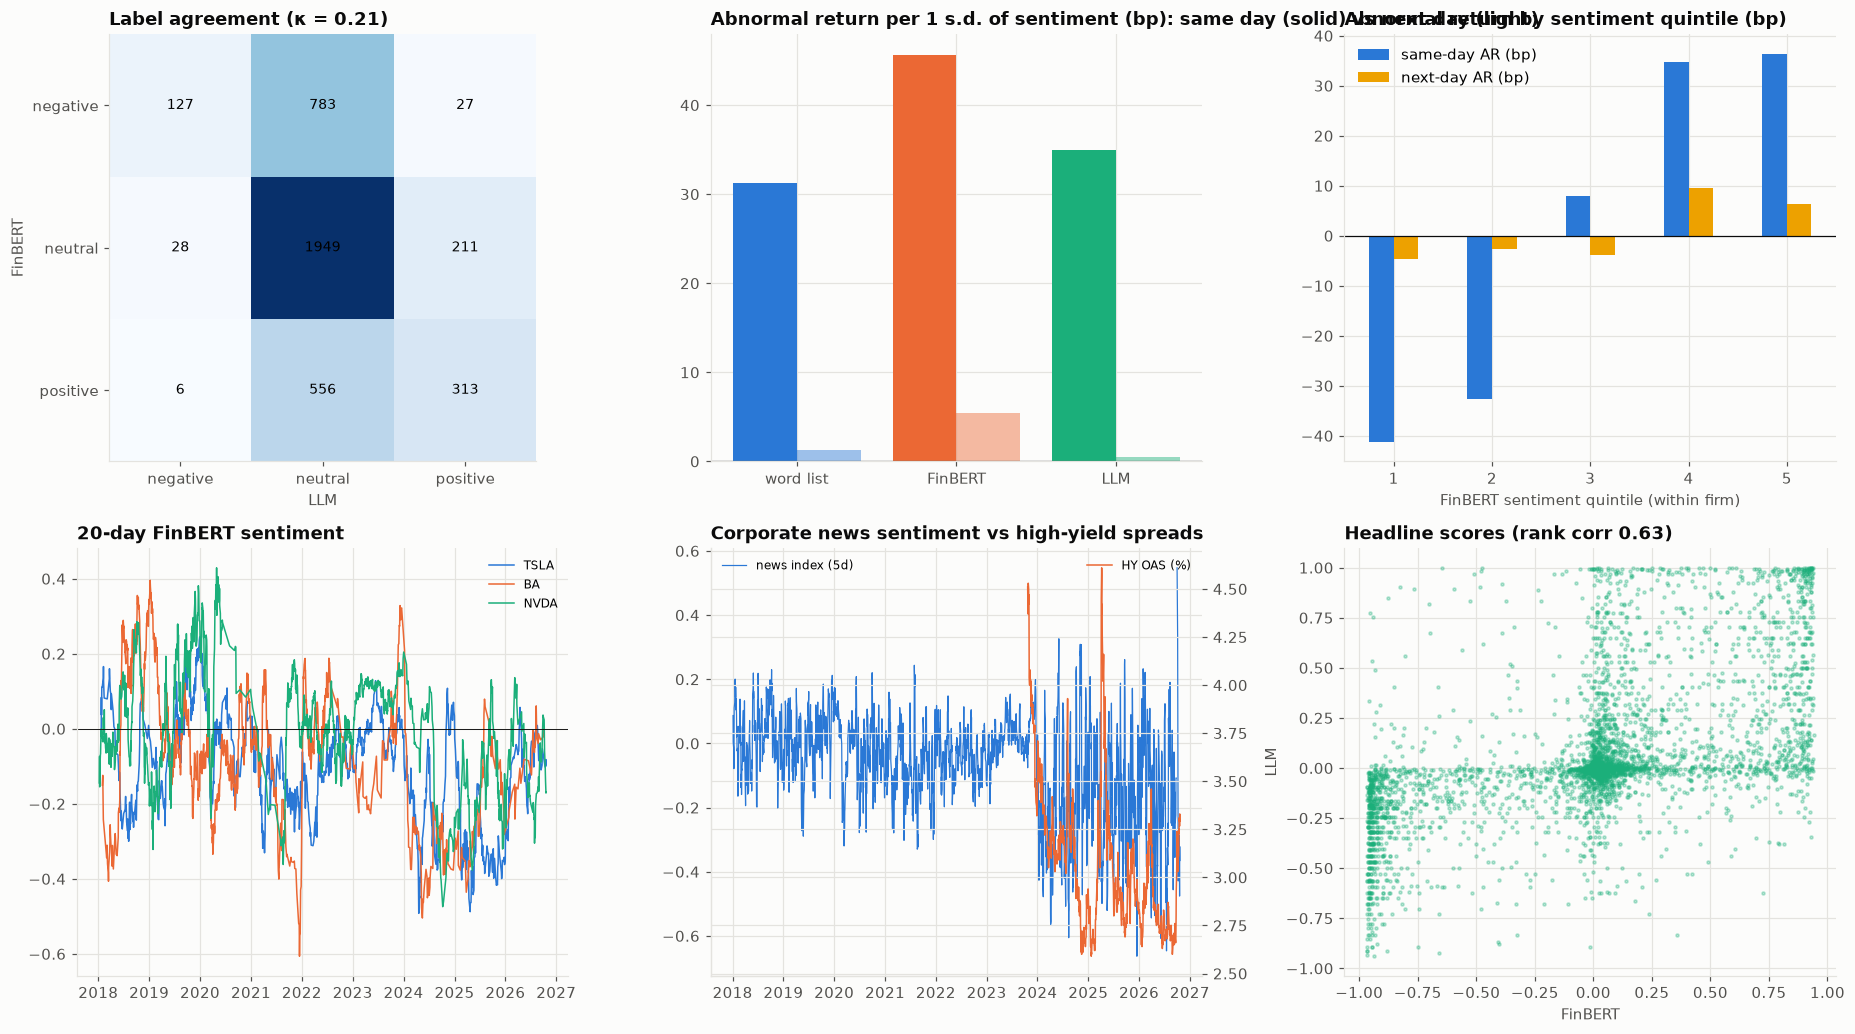

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
im = a.imshow(CROSS.to_numpy(), cmap="Blues")
a.grid(False)
a.set_xticks(range(3), CROSS.columns)
a.set_yticks(range(3), CROSS.index)
a.set_xlabel("LLM")
a.set_ylabel("FinBERT")
for i in range(3):
    for j in range(3):
        a.text(j, i, CROSS.iat[i, j], ha="center", va="center", fontsize=9)
a.set_title(
    f"Label agreement (κ = {AGREE['Cohen' + chr(39) + 's kappa']:.2f})"
)
a = ax[0, 1]
for k, (m, c) in enumerate(zip(["wordlist", "finbert", "llm"], PALETTE)):
    a.bar(k - 0.2, REG_C.loc[m, "same-day bp"], width=0.4, color=c)
    a.bar(k + 0.2, REG_C.loc[m, "next-day bp"], width=0.4, color=c, alpha=0.45)
a.set_xticks(range(3), ["word list", "FinBERT", "LLM"])
a.axhline(0, color=INK, lw=0.8)
a.set_title(
    "Abnormal return per 1 s.d. of sentiment (bp): same day (solid) vs next"
    " day (light)"
)
a = ax[0, 2]
QT.plot.bar(ax=a, color=[PALETTE[0], PALETTE[3]])
a.axhline(0, color=INK, lw=0.8)
a.tick_params(axis="x", rotation=0)
a.set_xlabel("FinBERT sentiment quintile (within firm)")
a.set_title("Abnormal return by sentiment quintile (bp)")
a = ax[1, 0]
for tk, c in zip(["TSLA", "BA", "NVDA"], PALETTE):
    s_ = (
        daily[daily["ticker"] == tk]
        .set_index("day")["finbert"]
        .rolling(20, min_periods=5)
        .mean()
    )
    a.plot(s_, color=c, lw=1, label=tk)
a.axhline(0, color=INK, lw=0.6)
a.legend(fontsize=8)
a.set_title("20-day FinBERT sentiment")
a = ax[1, 1]
a.plot(idx_s, color=PALETTE[0], lw=0.8, label="news index (5d)")
a2 = a.twinx()
a2.plot(oas.loc["2020":], color=PALETTE[1], lw=1, label="HY OAS (%)")
a.set_title("Corporate news sentiment vs high-yield spreads")
a.legend(loc="upper left", fontsize=8)
a2.legend(loc="upper right", fontsize=8)
a = ax[1, 2]
a.scatter(S["finbert"], S["llm"], s=4, alpha=0.3, color=PALETTE[2])
a.set_xlabel("FinBERT")
a.set_ylabel("LLM")
a.set_title(f"Headline scores (rank corr {AGREE['rank corr of scores']:.2f})")
fig.tight_layout()
save_fig(fig, "01_news_sentiment_finbert_llm")
plt.show()

In [10]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Same-day vs next-day effect (bp per s.d.)",
        "Next-day abnormal return by FinBERT quintile (bp)",
        "Daily news sentiment (20-day mean)",
        "News index and HY OAS",
    ),
    specs=[[{}, {}], [{}, {"secondary_y": True}]],
)
dash.add_trace(
    go.Bar(
        x=REG_C.index,
        y=REG_C["same-day bp"],
        name="same day",
        marker_color=PALETTE[0],
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=REG_C.index,
        y=REG_C["next-day bp"],
        name="next day",
        marker_color=PALETTE[3],
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=QT.index,
        y=QT["next-day AR (bp)"],
        marker_color=PALETTE[3],
        showlegend=False,
    ),
    1,
    2,
)
for tk, c in zip(list(COMPANIES)[:6], PALETTE):
    s_ = (
        daily[daily["ticker"] == tk]
        .set_index("day")["finbert"]
        .rolling(20, min_periods=5)
        .mean()
    )
    dash.add_trace(
        go.Scatter(x=s_.index, y=s_, name=tk, line=dict(color=c, width=1)),
        2,
        1,
    )
dash.add_trace(
    go.Scatter(
        x=idx_s.index, y=idx_s, name="news index", line=dict(color=PALETTE[0])
    ),
    2,
    2,
)
dash.add_trace(
    go.Scatter(
        x=oas.loc["2020":].index,
        y=oas.loc["2020":],
        name="HY OAS",
        line=dict(color=PALETTE[1]),
    ),
    2,
    2,
    secondary_y=True,
)
dash.update_layout(
    height=860,
    width=1400,
    template="simple_white",
    barmode="group",
    title="News sentiment: FinBERT vs open LLM vs a finance word list",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**The headlines.** 75,342 unique headlines on ten large U.S. companies, from January 2018 to October 2026, mapped to 2,174 trading days.

FNSPID supplies 84% of them (dense up to 2023), The Guardian 10%, the New York Times 4%, and the companies' 8-K press releases the rest. Coverage is uneven, from 1,309 headlines for Pfizer to 11,440 for Tesla.

**Do the three measures agree?** On a stratified sample of 4,000 headlines:

- **Labels:** FinBERT and Qwen2.5-1.5B give the same label 60% of the time, but Cohen's κ is only 0.21, because most headlines are neutral.
- **Scores:** the rank correlation of the continuous scores is much higher (0.63), and they point in opposite directions on fewer than 1% of headlines.
- **Where they differ:** the main disagreement is 783 headlines that FinBERT calls negative and the LLM neutral.

FinBERT also misreads market-wrap headlines. "Stock Alert: Boeing Surges On Consecutive Day" gets −0.48 from FinBERT and +1.00 from the LLM, and "U.S. stocks rally on coronavirus drug hopes" gets −0.88 against +0.85. The LLM, which is told which company the question is about, reads them correctly.

**What headlines say about returns** (market-adjusted returns, standardised sentiment, t-statistics clustered by date):

| Measure | Same day (bp per 1 s.d.) | t | Next day (bp per 1 s.d.) | t |
| --- | --- | --- | --- | --- |
| FinBERT | **26.8** | 11.8 | 3.2 | 1.6 |
| LLM (sample) | **34.9** | 6.3 | 0.5 | 0.1 |
| Word list | 15.8 | 7.2 | −1.3 | −0.7 |

**On the same day, sentiment explains returns strongly**, for every measure. On the common sample of 2,960 firm-days, FinBERT is strongest (45.7 bp, t = 8.7), then the LLM (34.9 bp) and the word list (31.2 bp).

The FinBERT quintile spread is large: −41 bp for the most negative fifth of firm-days against +36 bp for the most positive.

**By the next day, the signal is mostly gone.** FinBERT keeps 3 bp per standard deviation (t = 1.6). The top two quintiles earn +6 to +10 bp the following day, against −3 to −5 bp for the bottom ones.

That is too small to trade after costs in these mega-caps. News on large stocks is priced within the day, as the efficient-market literature would predict.

**Much of the same-day effect is reverse causality:** many headlines simply describe the price move ("shares jump…").

**Credit.** An index of the ten companies' FinBERT sentiment (5-day average) does not predict the next week's credit performance:

- HYG minus IEF returns: −1.7 bp per s.d., t = −0.4;
- changes in the ICE BofA high-yield spread: +0.6 bp, t = 0.6, on the 743 days FRED provides.

Credit spreads respond to macro and rates news more than to company headlines.

**Limitations**

- Headlines only, not full articles, and the sources are unevenly spread across companies and years (FNSPID ends in 2023).
- The LLM scores a sample of 4,000 headlines.
- Returns are daily, so intraday timing is approximated by the 16:00 rule.
- Ten mega-caps only. Sentiment effects are larger in small, less-covered stocks.
- FRED provides only the last three years of the high-yield spread.

In [11]:
daily.to_csv(
    OUT_DIR / "daily_company_sentiment.csv", index=False
# headline texts stay in data/ (publishers' content); only scores are exported
)
AGREE.to_csv(OUT_DIR / "model_agreement.csv", header=["value"])
CROSS.to_csv(OUT_DIR / "label_crosstab.csv")
REG_C.to_csv(OUT_DIR / "return_regressions_common_sample.csv")
REG.to_csv(OUT_DIR / "return_regressions_all.csv")
QT.to_csv(OUT_DIR / "quintile_returns.csv")
CREDIT.to_csv(OUT_DIR / "credit_lead_lag.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_news_sentiment_finbert_llm.png, credit_lead_lag.csv, daily_company_sentiment.csv, dashboard.html, dashboard.png, label_crosstab.csv, model_agreement.csv, quintile_returns.csv, return_regressions_all.csv, return_regressions_common_sample.csv


## References

### Finance and regulation

- Tetlock, P. C. (2007). Giving content to investor sentiment: The role of media in the stock market. *The Journal of Finance, 62*(3), 1139–1168. https://doi.org/10.1111/j.1540-6261.2007.01232.x
- Loughran, T., & McDonald, B. (2011). When is a liability not a liability? Textual analysis, dictionaries, and 10-Ks. *The Journal of Finance, 66*(1), 35–65. https://doi.org/10.1111/j.1540-6261.2010.01625.x
- Fama, E. F. (1970). Efficient capital markets: A review of theory and empirical work. *The Journal of Finance, 25*(2), 383–417. https://doi.org/10.2307/2325486
- Ke, Z. T., Kelly, B. T., & Xiu, D. (2019). *Predicting returns with text data* (NBER Working Paper No. 26186). National Bureau of Economic Research. https://doi.org/10.3386/w26186
- Lopez-Lira, A., & Tang, Y. (2023). Can ChatGPT forecast stock price movements? Return predictability and large language models. *arXiv*. https://arxiv.org/abs/2304.07619

### Machine learning and deep learning

- Araci, D. (2019). FinBERT: Financial sentiment analysis with pre-trained language models. *arXiv*. https://arxiv.org/abs/1908.10063
- Dong, Z., Fan, X., & Peng, Z. (2024). FNSPID: A comprehensive financial news dataset in time series. *arXiv*. https://arxiv.org/abs/2402.06698
- Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., … Rush, A. M. (2020). Transformers: State-of-the-art natural language processing. In *Proceedings of EMNLP 2020: System Demonstrations*. https://doi.org/10.18653/v1/2020.emnlp-demos.6
- Qwen Team. (2024). Qwen2.5 technical report. *arXiv*. https://arxiv.org/abs/2412.15115
- Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement, 20*(1), 37–46. https://doi.org/10.1177/001316446002000104